# Week 4 · Part C — Part-to-whole legality, and the pie-ranking experiment
**Data Visualization (CDB601220)**

1. **C.1** — the three part-to-whole conditions, **tested in code** on three share tables.
2. **C.2** — the pie-ranking experiment: this notebook **generates the stimuli and runs the timed trial on a real reader**.
3. **C.3** — scores whatever the reader actually did.
4. **C.4** — one sentence: when will I draw a pie?

> **Important — read before you run C.2.** The experiment needs a **real person**. This notebook does **not** contain, invent or simulate any reader results. Until you run the trial (or type in a real reader's responses), C.3 prints "no data yet". Invented results score zero.
>
> **How to run:** keep the notebook in `week4/assignments/`, run *Restart & Run All* for C.1 and the stimuli. For the experiment set `RUN_EXPERIMENT = True` in the C.2 cell and run that cell once per reader.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

HERE = Path.cwd()                      # run the notebook from week4/assignments
DATA = HERE / "data"
OUT  = HERE / "outputs"; OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(HERE))

import tslib as T                      # Week 4 toolkit (imports Week 3's vizlib)
from tslib import PALETTE, style_defaults, save_fig
style_defaults()
BLUE, ORANGE, GREEN = PALETTE["series"]
PINK, GREY, INK = PALETTE["series_4th"], PALETTE["muted"], PALETTE["ink"]
SOFT = PALETTE["ink_soft"]
SRC = "Source: CDB601220 Week 4 synthetic course data (Superior University Lahore)."

import time
PC = OUT / "partC"; PC.mkdir(exist_ok=True)

---
## C.1 · The three conditions, tested in code  *(3 marks)*
Slide 32: a pie / stacked bar / treemap of shares is legal only if **(1)** the parts are **exclusive**, **(2)** the whole is **meaningful** (the parts add to something you would actually want to talk about), and **(3)** the **share is the question** being asked.

In [2]:
# ---- table 1: the four touch_* columns of case08_channel_attrib.csv
c8 = pd.read_csv(DATA / "case08_channel_attrib.csv")
tc = ["touch_search", "touch_social", "touch_email", "touch_direct"]
ex8 = T.exclusivity_check(c8, tc)
print("TABLE 1  touch_* columns")
print("  shares_pct:", ex8["shares_pct"])
print(f"  sum = {ex8['sum_pct']}%   exclusive = {ex8['exclusive']}   customers in 2+ channels = {ex8['n_multi']} ({ex8['pct_multi']}%)")

# ---- table 2: shares_eight.csv
s8 = pd.read_csv(DATA / "shares_eight.csv")
tot8 = float(s8.share_pct.sum())
assert abs(s8.share_pct.sum() - 100) < 1e-6                         # slide-32 assert
print("\nTABLE 2  shares_eight.csv")
print(f"  rows = {len(s8)}   sum = {tot8:.6f}%   each subcategory belongs to exactly one slice: {s8.subcategory.is_unique}")
print(f"  smallest = {s8.share_pct.min()}%, largest = {s8.share_pct.max()}%;  C, H, G = {s8.set_index('slice').share_pct[['C','H','G']].tolist()}")

# ---- table 3: premium vs other, 2025Q4
c9 = pd.read_csv(DATA / "case09_premium_share.csv")
q4 = c9[c9.quarter == "2025Q4"].iloc[0]
other = q4.total_revenue_pkr_m - q4.premium_revenue_pkr_m
print("\nTABLE 3  premium vs other, 2025Q4")
print(f"  premium {q4.premium_revenue_pkr_m} + other {other} = {q4.premium_revenue_pkr_m + other} = total {q4.total_revenue_pkr_m}   "
      f"-> exclusive and exhaustive: {abs(q4.premium_revenue_pkr_m + other - q4.total_revenue_pkr_m) < 1e-9}")
print(f"  premium share in 2025Q4 = {q4.premium_revenue_pkr_m / q4.total_revenue_pkr_m * 100:.1f}%;  the same quarter's total is {q4.total_revenue_pkr_m / c9.total_revenue_pkr_m.iloc[0] * 100:.0f}% of 2024Q1's")

verdicts = pd.DataFrame([
    ["touch_* columns", "NO - 27.6% of customers sit in 2+ columns", "NO - sums to 131%", "reach, not share", "NEITHER as a share (bars of reach only)"],
    ["shares_eight (8 rows)", "yes - one subcategory per slice", "yes - eight-category total, sums to 100", "'how big is each part?' - yes", "BAR (sorted). A pie is legal but weak for 8 slices"],
    ["premium vs other, 2025Q4", "yes - premium + other = total", "yes - total revenue", "NO - the question is 'is premium growing?' (a trend)", "NEITHER as one-quarter pie; show revenue over time"],
], columns=["table", "1 exclusive?", "2 meaningful whole?", "3 share is the question?", "verdict"])
display(verdicts)
(PC / "C1_verdicts.csv").write_text(verdicts.to_csv(index=False))

TABLE 1  touch_* columns
  shares_pct: {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58}
  sum = 130.98%   exclusive = False   customers in 2+ channels = 1105 (27.62%)

TABLE 2  shares_eight.csv
  rows = 8   sum = 100.000000%   each subcategory belongs to exactly one slice: True
  smallest = 2.4%, largest = 24.6%;  C, H, G = [15.0, 13.1, 11.2]

TABLE 3  premium vs other, 2025Q4
  premium 228.0 + other 372.0 = 600.0 = total 600.0   -> exclusive and exhaustive: True
  premium share in 2025Q4 = 38.0%;  the same quarter's total is 60% of 2024Q1's


,table,1 exclusive?,2 meaningful whole?,3 share is the question?,verdict
0,touch_* columns,NO - 27.6% of customers sit in 2+ columns,NO - sums to 131%,"reach, not share",NEITHER as a share (bars of reach only)
1,shares_eight (8 rows),yes - one subcategory per slice,"yes - eight-category total, sums to 100",'how big is each part?' - yes,BAR (sorted). A pie is legal but weak for 8 sl...
2,"premium vs other, 2025Q4",yes - premium + other = total,yes - total revenue,NO - the question is 'is premium growing?' (a ...,NEITHER as one-quarter pie; show revenue over ...


569

**Verdicts and the argument for each**

1. **`touch_*` columns → neither a pie nor any part-to-whole chart.** `exclusivity_check` shows the four shares sum to **130.98%** and **1,105 customers (27.6%)** sit in two or more columns, so condition 1 fails and no pie, stacked bar or treemap of them is valid. Plain bars of *reach* (percent of customers touched, labelled as not summing to 100) are fine.
2. **`shares_eight.csv` → bar chart (sorted horizontal bars).** The eight slices are exclusive sub-categories, the whole is the eight-category net revenue and sums to exactly 100, and the question "how big is each part?" is about *ranking and magnitude*. A pie is **legal**, but it uses angle, the 3rd-best channel, and the middle three slices (C 15.0%, H 13.1%, G 11.2%) are within 3.8 points of each other — exactly where angle fails. Bars use position on a common scale.
3. **`premium` vs `other`, 2025Q4 → neither, as a one-quarter pie.** Conditions 1 and 2 pass (premium + other = total revenue of 600). Condition 3 fails: the claim being made is "a record, premium is *growing*", a **trend** question, and a single-quarter share cannot answer it (premium revenue actually fell 5% while the total fell 40%). The honest chart shows premium and other revenue over the eight quarters.

---
## C.2 · Run the ranking on a real reader  *(3 marks)*
Stimulus 1: the eight shares as a **pie, no numbers**, file order, `startangle=90, counterclock=False`.
Stimulus 2: the same eight as **sorted horizontal bars**.

true order, largest first: ABCHGDEF   (used only for scoring, never shown to the reader)


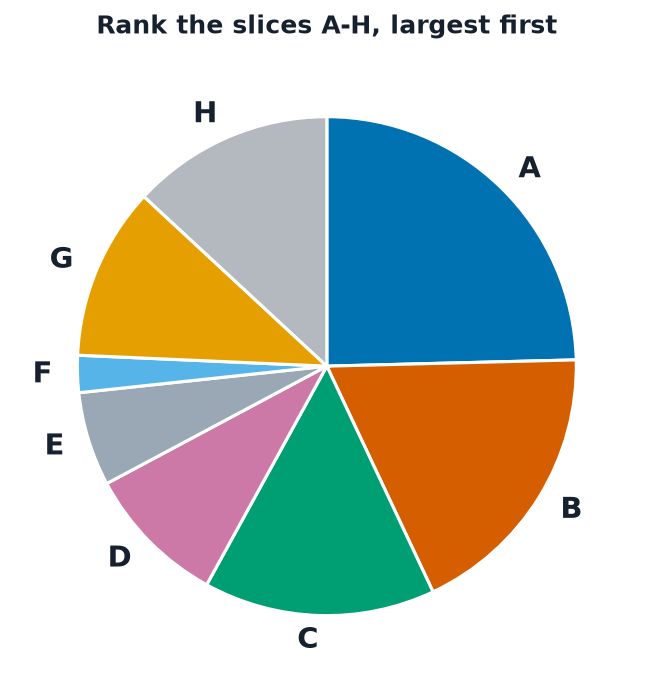

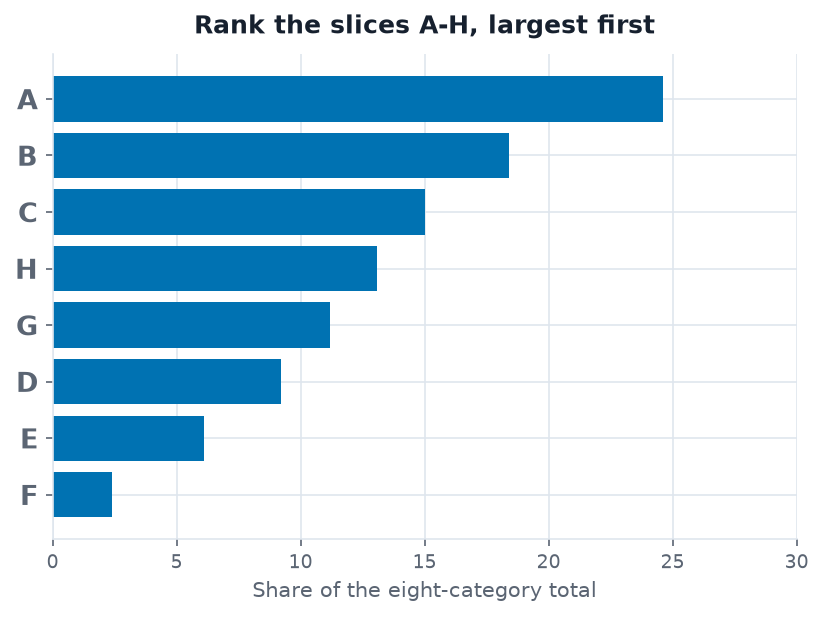

In [3]:
true_order = "".join(s8.sort_values("share_pct", ascending=False).slice)
print("true order, largest first:", true_order, "  (used only for scoring, never shown to the reader)")

# -------- stimulus 1: pie, letters only, no numbers
fig, ax = plt.subplots(figsize=(5.4, 5.4))
ax.pie(s8.share_pct, labels=s8.slice, startangle=90, counterclock=False,
       colors=[BLUE, ORANGE, GREEN, PINK, GREY, "#56B4E9", "#E69F00", "#B4B8BF"],
       wedgeprops=dict(edgecolor="white", linewidth=1.5), textprops=dict(fontsize=14, fontweight="bold"))
ax.set_title("Rank the slices A-H, largest first", loc="center")
fig.savefig(PC / "stimulus_pie.png", dpi=200, bbox_inches="tight", facecolor="white"); plt.show()

# -------- stimulus 2: the same eight as sorted horizontal bars (letters; no values)
srt = s8.sort_values("share_pct", ascending=True)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.barh(srt.slice, srt.share_pct, color=BLUE)
ax.set_xlim(0, 30); ax.set_xlabel("Share of the eight-category total"); ax.set_yticks(range(len(srt))); ax.set_yticklabels(srt.slice, fontsize=13, fontweight="bold")
ax.set_title("Rank the slices A-H, largest first", loc="center")
fig.savefig(PC / "stimulus_bars.png", dpi=200, bbox_inches="tight", facecolor="white"); plt.show()

In [4]:
# ===== SET THIS TO True TO RUN THE TRIAL ON A REAL READER (needs a human at the keyboard) =====
RUN_EXPERIMENT = False
READER = "reader_1"          # a label for this person, e.g. initials. Change it for each new reader.

from IPython.display import Image, clear_output
RESULTS = OUT / "pie_ranking_results.csv"

def run_trial(stimulus, image_path, reader):
    """Show the stimulus, start the clock, collect the A-H order, stop the clock."""
    display(Image(filename=str(image_path)))
    t0 = time.perf_counter()
    order = input("Type the letters A-H, largest first (e.g. ACBHGDEF), then Enter: ").strip().upper()
    seconds = time.perf_counter() - t0
    clear_output()
    if sorted(order) != list("ABCDEFGH"):
        print("Invalid answer - need each of A-H exactly once. Trial discarded; run the cell again."); return None
    return {"reader": reader, "stimulus": stimulus, "order": order, "seconds": round(seconds, 2)}

if RUN_EXPERIMENT:
    rows = []
    for stim, path in (("pie", PC / "stimulus_pie.png"), ("sorted_bars", PC / "stimulus_bars.png")):
        r = run_trial(stim, path, READER)
        if r: rows.append(r)
    new = pd.DataFrame(rows)
    if len(new):
        old = pd.read_csv(RESULTS) if RESULTS.exists() else pd.DataFrame(columns=new.columns)
        pd.concat([old, new], ignore_index=True).to_csv(RESULTS, index=False)
        print("saved:", RESULTS); display(new)
else:
    print("RUN_EXPERIMENT is False - no trial was run. Stimuli are saved in outputs/partC/ if you prefer to run it on paper.")

# ---- OPTIONAL: if you ran it on paper / with a phone stopwatch, type the REAL responses here.
# Format: {"reader": "R1", "stimulus": "pie", "order": "ABHCGDEF", "seconds": 41.3}
# Leave empty if you have none. Do NOT put in made-up data.
MANUAL_ENTRIES = []
if MANUAL_ENTRIES:
    new = pd.DataFrame(MANUAL_ENTRIES)
    old = pd.read_csv(RESULTS) if RESULTS.exists() else pd.DataFrame(columns=new.columns)
    pd.concat([old, new], ignore_index=True).drop_duplicates().to_csv(RESULTS, index=False)
    print("manual entries saved to", RESULTS)

RUN_EXPERIMENT is False - no trial was run. Stimuli are saved in outputs/partC/ if you prefer to run it on paper.


**Protocol notes (state these in your write-up):** the pie is shown first, then the bars — so a reader sees the same eight letters twice, which can help the second stimulus (an order effect). The sorted bars put the letters in rank order, so the second stimulus is nearly trivial *by construction*; its time and error count measure "reading a sorted list" more than "reading a bar length". Both are honest limitations to report, not to hide.

---
## C.3 · Score it  *(2 marks)*
Against the true order, how many letters did the reader place wrongly on each stimulus, and where in the ranking did the errors fall? The deck predicts most readers get the top two and the bottom one right and disagree about the middle, because **C (15.0%), H (13.1%) and G (11.2%)** are close.

In [5]:
true_order = "".join(s8.sort_values("share_pct", ascending=False).slice)
if not RESULTS.exists() or len(pd.read_csv(RESULTS)) == 0:
    print("No reader data yet - outputs/pie_ranking_results.csv does not exist.")
    print("Run the trial in C.2 (RUN_EXPERIMENT = True) on a real person, then re-run this cell.")
    print("Nothing is scored and nothing is invented.")
else:
    res = pd.read_csv(RESULTS)
    def score(order):
        wrong_pos = [i + 1 for i, (a, b) in enumerate(zip(order, true_order)) if a != b]
        return pd.Series({"letters_wrong": len(wrong_pos), "wrong_at_ranks": wrong_pos,
                          "top2_right": order[:2] == true_order[:2], "bottom1_right": order[-1] == true_order[-1]})
    scored = pd.concat([res, res.order.apply(score)], axis=1)
    display(scored)
    print("true order:", true_order)
    print(f"readers in file: {res.reader.nunique()}  | n = {res.reader.nunique()} - state plainly what that can and cannot support")
    print(scored.groupby("stimulus")[["seconds", "letters_wrong"]].mean().round(2))

No reader data yet - outputs/pie_ranking_results.csv does not exist.
Run the trial in C.2 (RUN_EXPERIMENT = True) on a real person, then re-run this cell.
Nothing is scored and nothing is invented.


**How to write the answer (after running):** report, per stimulus, the seconds and the number of letters placed wrongly, and *which ranks* the errors fell on (the middle ranks 3–5 are C, H, G). Then say plainly what a sample of one reader can and cannot support: it cannot show that pies are slower or worse in general, only what happened with this person; a result that disagrees with the deck is fine if you explain it honestly.

---
## C.4 · State your rule  *(1 mark)*
> **From now on I will draw a pie only when there are two or three exclusive parts that add up to a whole worth naming, the question is "what fraction of the whole is this one part?", and the percentages are printed on the slices — otherwise I draw sorted bars.**